# Structural xP model

Predicts every FPL player's points for each gameweek by predicting each scoring component and combining them with
the scoring rules (which reproduce `total_points` exactly for every position). The model is in `src/structural.py`
(CLI: `cd src && python structural.py`); this notebook runs it and evaluates it.

| Component | Model | Trained on |
|---|---|---|
| minutes: P(plays), then P(60+ \| plays) | gradient boosting; plays stage monotonic in the FPL status | every player with a fixture, all positions pooled (position flags) |
| team goals conceded, $P(CS)=e^{-\lambda}$ | Poisson GLM, shared by all positions | team-fixture rows |
| goals, assists, saves (GK), given 1-59 or 60+ | Poisson GLMs per position; goals and assists also use pre-deadline set-piece duties (penalty, corner, free-kick taker order) | appearances of the position |
| bonus, given 1-59 or 60+ | Poisson GLM | appearances, all positions pooled (position flags) |
| pens saved, cards, own goals, missed pens | mean per appearance | appearances |

Every model for gameweek *gw* is fitted on gameweeks < *gw* only. Goal, assist and goals-conceded models are trained
on xG, xA and team xGA (less noise); predictions are scored against `total_points`.

- `pred`: unconditional expected points (includes the chance of not playing), what a team is picked on.
- `pred_if_plays`: $E[\text{pts} \mid \text{plays}]$.
- `e_*`: expected points per component; they sum to `pred`.

The minutes model uses each player's last FPL status and chance of playing before the deadline, from the git history
of vaastav's `players_raw.csv` (`src/build_availability.py`, run once per season). Snapshots are a median of 44 hours
old at the deadline in 2023-24 (over a week for GW5, 21, 22, 27, 30) and 39 hours in 2024-25 (over a week for GW4, 8,
21, 23, 30, 33).

**Season.** Set `SEASON` in the next cell (`"23-24"` or `"24-25"`, see `config.SEASONS`). The season's inputs come from
`src/build_data.py` and `src/build_availability.py`. `HISTORY` adds the previous season to every gameweek's training
data (`["22-23"]` for 2023-24, used from its GW26 because FPL's xG starts at GW16; `["23-24"]` for 2024-25), which also
lets GW1-4 be predicted. It cut RMSE from 1.854 to 1.847 (2023-24) and from 1.877 to 1.871 (2024-25).

**Metric.** RMSE: squared error is minimised by the mean, which is what the optimiser needs (MAE is minimised by
the median). Spearman is reported because picking a team depends on ranking players.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import pandas as pd
from sklearn import metrics

sys.path.insert(0, "../src")
import config  # noqa: E402  (paths are relative to src/, which resolve the same from notebooks/)
import structural  # noqa: E402

SEASON = "23-24"  # or "24-25"
HISTORY = []  # earlier seasons to train on as well: ["22-23"] for 23-24, ["23-24"] for 24-25
p = config.paths(SEASON)
GWS = range(1 if HISTORY else config.FIRST_GW, config.LAST_GW + 1)
data = structural.load(SEASON)  # (players, team-fixture table), loaded once

## Predict every position, every gameweek (from GW5, or GW1 with `HISTORY`)

In [2]:
preds = structural.walk_forward(gws=GWS, data=data, history=HISTORY)
out = config.output_path(SEASON, HISTORY)
os.makedirs(os.path.dirname(out), exist_ok=True)
preds.to_csv(out, index=False)
preds.head()

,season,pos,round,fpl_id,name,team,opponent_team,fixture,value,total_points,...,e_cs,e_gc,e_goals,e_assists,e_bonus,e_saves,e_other,pred,pred_if_plays,history
0,23-24,GK,5,17,Aaron Ramsdale,Arsenal,Everton,43,50,0,...,1.238028,-0.347573,0.001516,0.002654,0.590401,0.381109,-0.012636,3.823201,3.879039,
1,23-24,GK,5,18,Rúnar Alex Rúnarsson,Arsenal,Everton,43,40,0,...,0.001003,-0.000288,0.000001,0.000002,0.000486,0.000537,-0.000012,0.003437,3.780188,
2,23-24,GK,5,28,Matt Turner,Nott'm Forest,Burnley,47,40,2,...,0.655807,-0.644091,0.001520,0.002660,0.284102,0.470719,-0.012664,2.730949,2.764627,
3,23-24,GK,5,49,Emiliano Martínez Romero,Aston Villa,Crystal Palace,41,49,2,...,1.048236,-0.368744,0.001427,0.002497,0.310405,0.433893,-0.011890,3.265662,3.521218,
4,23-24,GK,5,53,Robin Olsen,Aston Villa,Crystal Palace,41,40,0,...,0.424434,-0.151650,0.000631,0.001104,0.132462,0.215384,-0.005258,1.400709,3.415424,


## Scores by position

- **Every player with a fixture** (`pred`): how the model is used, before the deadline.
- **Players who played** (`pred_if_plays`).

In [3]:
def table(cols, played_only):
    t = structural.score(preds, cols, played_only=played_only)
    return t.set_index("pos")[["n", "RMSE", "R2", "Spearman", "MAE"]].round(3)


print("Every player with a fixture")
display(table(("pred",), played_only=False))
print("Players who played")
display(table(("pred_if_plays",), played_only=True))

Every player with a fixture


,n,RMSE,R2,Spearman,MAE
pos,,,,,
DEF,8432,1.873,0.269,0.642,0.956
FWD,3388,2.010,0.349,0.759,0.944
GK,2988,1.364,0.436,0.658,0.582
MID,11293,1.903,0.363,0.765,0.883
all,26101,1.854,0.341,0.721,0.880


Players who played


,n,RMSE,R2,Spearman,MAE
pos,,,,,
DEF,3319,2.818,0.081,0.321,2.065
FWD,1249,3.145,0.088,0.442,2.218
GK,674,2.589,0.021,0.160,2.004
MID,4618,2.825,0.130,0.436,1.846
all,9860,2.850,0.109,0.404,1.978


## Per-gameweek RMSE by position (players who played)

A single haul can move one gameweek's RMSE a lot, so the season figure in each panel's corner is the one to judge by.

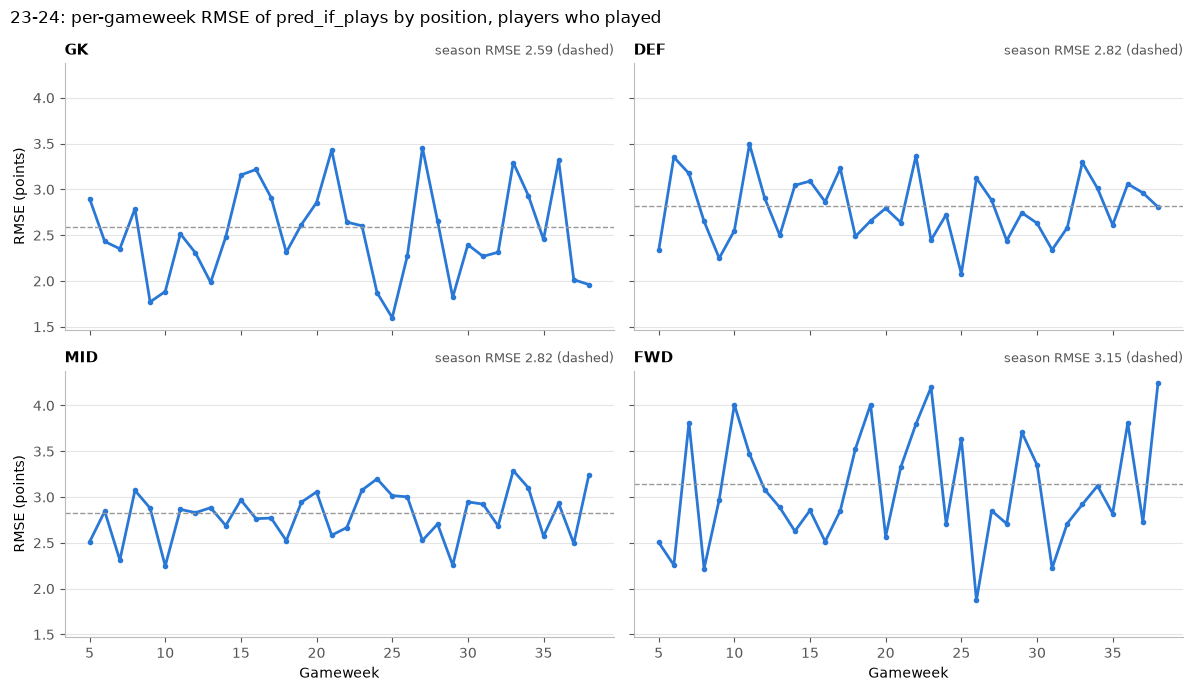

pos,DEF,FWD,GK,MID
round,,,,
5,2.34,2.51,2.90,2.51
6,3.35,2.26,2.43,2.84
7,3.17,3.81,2.35,2.31
8,2.65,2.22,2.79,3.07
9,2.25,2.97,1.77,2.88
10,2.55,4.01,1.89,2.25
11,3.50,3.47,2.52,2.87
12,2.91,3.08,2.31,2.83
13,2.50,2.89,1.98,2.88


In [4]:
played = preds[preds.played & preds.has_target]
rmse = (
    played.groupby(["pos", "round"])
    .apply(lambda g: metrics.root_mean_squared_error(g.total_points, g.pred_if_plays))
    .rename("rmse")
    .reset_index()
)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for ax, pos in zip(axes.flat, config.POSITIONS):
    d = rmse[rmse.pos == pos]
    ax.plot(d["round"], d.rmse, color="#2a78d6", lw=2, marker="o", ms=3)
    g = played[played.pos == pos]
    season = metrics.root_mean_squared_error(g.total_points, g.pred_if_plays)
    ax.axhline(season, color="#999", lw=1, ls="--")
    ax.text(
        1,
        1.02,
        f"season RMSE {season:.2f} (dashed)",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=9,
        color="#555",
    )
    ax.set_title(pos, loc="left", fontsize=11, fontweight="bold")
    ax.grid(axis="y", color="#e5e5e5", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#bbb")
    ax.tick_params(colors="#555")
for ax in axes[1]:
    ax.set_xlabel("Gameweek")
for ax in axes[:, 0]:
    ax.set_ylabel("RMSE (points)")
fig.suptitle(
    f"{SEASON}: per-gameweek RMSE of pred_if_plays by position, players who played",
    x=0.01,
    ha="left",
    fontsize=12,
)
fig.tight_layout()
plt.show()

rmse.pivot(index="round", columns="pos", values="rmse").round(2)  # table view

## Component calibration: mean predicted vs actual

In [5]:
q = preds[preds.has_target].copy()
q["played_y"] = q.minutes > 0
q["full_y"] = q.minutes >= 60
cal = q.groupby("pos").agg(
    p_play=("p_play", "mean"),
    played=("played_y", "mean"),
    p60=("p60", "mean"),
    full=("full_y", "mean"),
)
full = q[q.full_y].merge(
    data[0][["fpl_id", "round", "clean_sheets"]], on=["fpl_id", "round"]
)
cal = cal.join(
    full.groupby("pos").agg(p_cs=("p_cs", "mean"), clean_sheet=("clean_sheets", "mean"))
)
cal.round(3)

,p_play,played,p60,full,p_cs,clean_sheet
pos,,,,,,
DEF,0.396,0.394,0.311,0.308,0.219,0.217
FWD,0.375,0.369,0.216,0.206,0.220,0.271
GK,0.232,0.226,0.225,0.218,0.221,0.209
MID,0.404,0.409,0.251,0.253,0.224,0.267


## Expected points per component (mean per appearance)

In [6]:
q[q.played_y].groupby("pos")[
    [c for c in q.columns if c.startswith("e_")] + ["pred_if_plays", "total_points"]
].mean().round(3)

,e_app,e_cs,e_gc,e_goals,e_assists,e_bonus,e_saves,e_other,pred_if_plays,total_points
pos,,,,,,,,,,
DEF,1.454,0.589,-0.381,0.223,0.128,0.168,0.000,-0.169,2.426,2.419
FWD,1.330,0.000,0.000,0.900,0.154,0.298,0.000,-0.106,3.007,3.079
GK,1.667,0.728,-0.468,0.000,0.003,0.241,0.578,-0.049,3.194,3.169
MID,1.348,0.124,0.000,0.542,0.245,0.182,0.000,-0.141,2.705,2.830


## One gameweek: top predicted players

In [7]:
gw21 = structural.walk_forward(gws=[21], data=data, history=HISTORY)
gw21.sort_values("pred", ascending=False)[
    ["pos", "name", "team", "p_play", "p_cs", "pred", "total_points"]
].head(15)

,pos,name,team,p_play,p_cs,pred,total_points
352,MID,Bukayo Saka,Arsenal,0.984461,0.355172,6.780173,3
349,MID,Martin Ødegaard,Arsenal,0.984237,0.355172,5.669608,3
499,MID,Cole Palmer,Chelsea,0.978039,0.353212,5.353886,10
408,MID,Pascal Groß,Brighton,0.981951,0.297337,5.041496,3
701,FWD,João Pedro Junqueira de Jesus,Brighton,0.978725,0.297337,4.989532,2
566,MID,Jarrod Bowen,West Ham,0.974188,0.234690,4.785653,2
179,DEF,Trent Alexander-Arnold,Liverpool,0.960495,0.303120,4.484816,0
734,FWD,Julián Álvarez,Man City,0.940617,0.323955,4.164957,2
691,FWD,Ollie Watkins,Aston Villa,0.983678,0.253342,4.141555,1
561,MID,Richarlison de Andrade,Spurs,0.941624,0.188151,4.026225,8


## Sample of players: predicted vs actual points

A random sample of players per position for a few gameweeks. Players are sampled among those with P(plays) ≥ 0.5,
which is known before the deadline (sampling on who actually played would select on the outcome). The prediction is
`pred`, the figure a team is picked on. Change `GWS`, `N` or `SEED` to look at others.

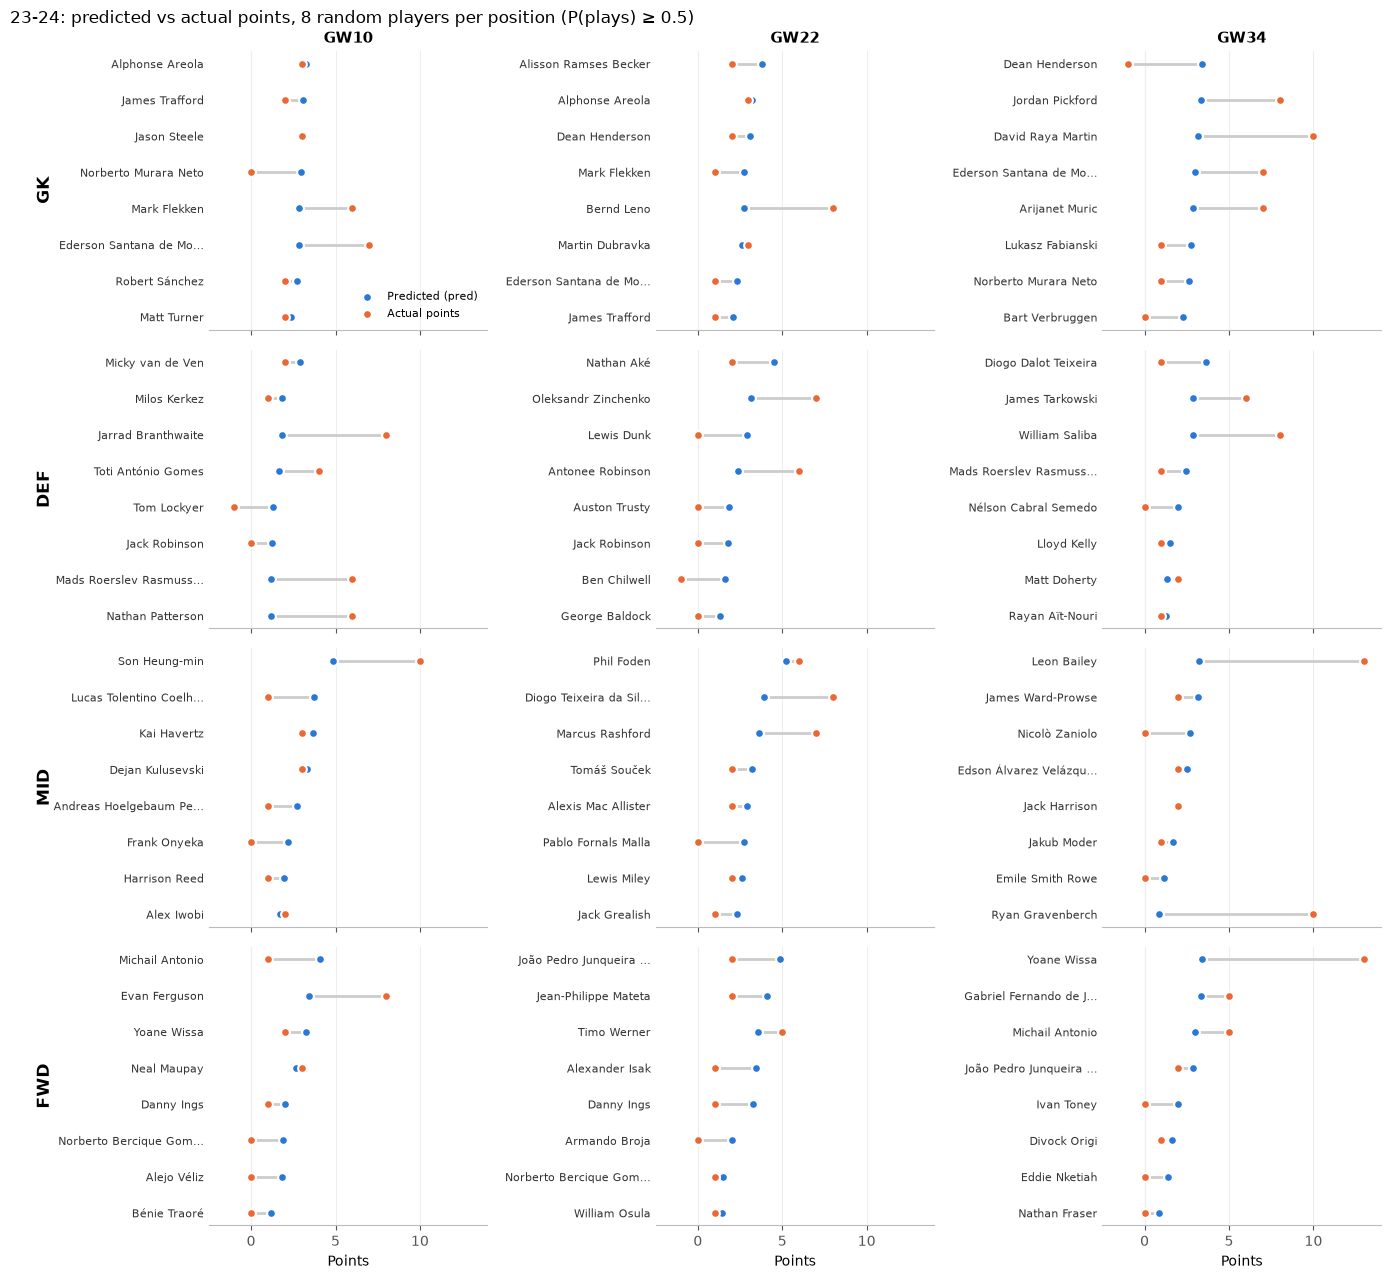

,pos,round,name,team,p_play,pred,total_points,minutes
3910,DEF,10,Micky van de Ven,Spurs,0.99,2.92,2,90
3895,DEF,10,Milos Kerkez,Bournemouth,0.94,1.85,1,8
3772,DEF,10,Jarrad Branthwaite,Everton,0.95,1.84,8,90
3886,DEF,10,Toti António Gomes,Wolves,0.85,1.66,4,90
3887,DEF,10,Tom Lockyer,Luton,0.95,1.32,-1,90
...,...,...,...,...,...,...,...,...
22452,MID,34,Edson Álvarez Velázquez,West Ham,0.94,2.51,2,74
22459,MID,34,Jack Harrison,Everton,0.90,2.02,2,90
22265,MID,34,Jakub Moder,Brighton,0.81,1.71,1,55
22205,MID,34,Emile Smith Rowe,Arsenal,0.61,1.13,0,0


In [10]:
GWS, N, SEED = [10, 22, 34], 8, 1
PRED, ACTUAL = "#2a78d6", "#eb6834"

pool = preds[preds["round"].isin(GWS) & (preds.p_play >= 0.5)]
sample = pool.groupby(["pos", "round"]).sample(
    n=N, random_state=SEED
)  # every group has well over N players

fig, axes = plt.subplots(len(config.POSITIONS), len(GWS), figsize=(14, 13), sharex=True)
xmax = max(sample.pred.max(), sample.total_points.max()) + 1
for r, pos in enumerate(config.POSITIONS):
    for c, gw in enumerate(GWS):
        ax = axes[r, c]
        d = sample[(sample.pos == pos) & (sample["round"] == gw)].sort_values("pred")
        y = range(len(d))
        ax.hlines(
            y,
            d[["pred", "total_points"]].min(axis=1),
            d[["pred", "total_points"]].max(axis=1),
            color="#ccc",
            lw=2,
        )
        ax.scatter(
            d.pred,
            y,
            color=PRED,
            s=40,
            zorder=3,
            label="Predicted (pred)",
            edgecolor="white",
            linewidth=1.5,
        )
        ax.scatter(
            d.total_points,
            y,
            color=ACTUAL,
            s=40,
            zorder=3,
            label="Actual points",
            edgecolor="white",
            linewidth=1.5,
        )
        ax.set_yticks(
            list(y),
            [n if len(n) <= 22 else n[:21] + "…" for n in d.name],
            fontsize=8,
            color="#333",
        )
        ax.set_xlim(-2.5, xmax)
        ax.axvline(0, color="#e5e5e5", lw=0.8, zorder=0)
        ax.grid(axis="x", color="#eee", lw=0.8)
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.spines["bottom"].set_color("#bbb")
        ax.tick_params(axis="y", length=0)
        ax.tick_params(axis="x", colors="#555")
        if r == 0:
            ax.set_title(f"GW{gw}", fontsize=11, fontweight="bold")
        if c == 0:
            ax.annotate(
                pos,
                xy=(-0.62, 0.5),
                xycoords="axes fraction",
                fontsize=12,
                fontweight="bold",
                rotation=90,
                va="center",
            )
for ax in axes[-1]:
    ax.set_xlabel("Points")
axes[0, 0].legend(frameon=False, loc="lower right", fontsize=8)
fig.suptitle(
    f"{SEASON}: predicted vs actual points, {N} random players per position (P(plays) ≥ 0.5)",
    x=0.01,
    ha="left",
    fontsize=12,
)
fig.tight_layout()
plt.show()

# table view
sample.sort_values(["pos", "round", "pred"], ascending=[True, True, False])[
    ["pos", "round", "name", "team", "p_play", "pred", "total_points", "minutes"]
].round(2)

## Data check: FPL's same-gameweek `xP` is not a pre-match forecast

`xP` in the source data correlates far more with the same gameweek's result than with the next one, and differs by
about 2 points between defenders who kept a clean sheet and those who did not. A pre-match forecast cannot do that, so
it was recorded after the match, and this model does not use it. Lagged xP features (`xP_rolling_k`, `xP_k_ewm`) only
use past gameweeks and would be fine.

In [9]:
r = data[0][data[0].minutes > 0].sort_values(["fpl_id", "kickoff_time"]).copy()
g = r.groupby("fpl_id").total_points
r["prev"], r["next"] = g.shift(1), g.shift(-1)
r = r.dropna(subset=["xP", "prev", "next"])
print(
    pd.DataFrame(
        {
            "corr(xP, points) previous GW": r.groupby("position").apply(
                lambda d: d.xP.corr(d.prev)
            ),
            "same GW": r.groupby("position").apply(lambda d: d.xP.corr(d.total_points)),
            "next GW": r.groupby("position").apply(lambda d: d.xP.corr(d.next)),
        }
    ).round(3)
)
d60 = r[(r.position == "DEF") & (r.minutes >= 60)]
print(
    f"\nDEF 60+ min: mean xP {d60[d60.clean_sheets == 1].xP.mean():.2f} with a clean sheet, "
    f"{d60[d60.clean_sheets == 0].xP.mean():.2f} without"
)

          corr(xP, points) previous GW  same GW  next GW
position                                                
DEF                              0.509    0.562    0.129
FWD                              0.555    0.577    0.216
GK                               0.481    0.459    0.012
MID                              0.557    0.606    0.264

DEF 60+ min: mean xP 4.14 with a clean sheet, 2.07 without
